In [13]:

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


PyTorch version: 2.14.1+cu130
OpenCV version: 4.14.0
GPU available: True
Device: cuda


In [14]:

from google.colab import files

uploaded = files.upload()


Saving archive (2).zip to archive (2) (1).zip


In [15]:

import zipfile
import os

zip_name = next(iter(uploaded))

extract_path = "/content/NEU_Dataset"

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print("Top-level files and folders:")
print(os.listdir(extract_path))


Dataset extracted successfully!
Top-level files and folders:
['NEU-DET']


In [16]:

dataset_path = "/content/NEU_Dataset/NEU-DET"

print("Contents of NEU-DET:")
print(os.listdir(dataset_path))


Contents of NEU-DET:
['validation', 'train']


In [17]:

train_path = "/content/NEU_Dataset/NEU-DET/train"
val_path = "/content/NEU_Dataset/NEU-DET/validation"

print("Training folder:")
print(os.listdir(train_path))

print("\nValidation folder:")
print(os.listdir(val_path))


Training folder:
['annotations', 'images']

Validation folder:
['annotations', 'images']


In [18]:

image_folder = "/content/NEU_Dataset/NEU-DET/train/images"

print("Contents of images folder:")
print(os.listdir(image_folder)[:20])

print("\nTotal items:", len(os.listdir(image_folder)))


Contents of images folder:
['scratches', 'pitted_surface', 'patches', 'rolled-in_scale', 'inclusion', 'crazing']

Total items: 6


Number of scratch images: 240
Image filename: scratches_1.jpg
Image shape: (200, 200)
Minimum pixel value: 75
Maximum pixel value: 249


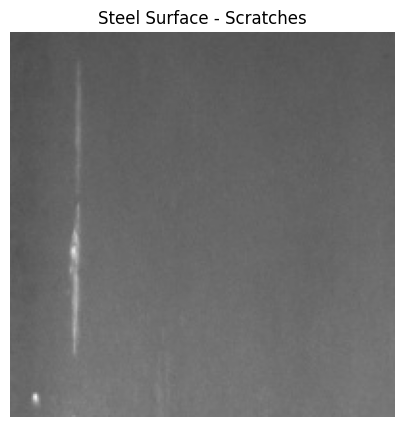

In [19]:

import os
import cv2
import matplotlib.pyplot as plt

image_folder = "/content/NEU_Dataset/NEU-DET/train/images"

# Select the scratches class
class_name = "scratches"

class_path = os.path.join(image_folder, class_name)

# Find image files inside this class
image_files = sorted([
    f for f in os.listdir(class_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

print("Number of scratch images:", len(image_files))

if image_files:
    image_path = os.path.join(class_path, image_files[0])

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if image is not None:
        print("Image filename:", image_files[0])
        print("Image shape:", image.shape)
        print("Minimum pixel value:", image.min())
        print("Maximum pixel value:", image.max())

        plt.figure(figsize=(5, 5))
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        plt.title("Steel Surface - Scratches")
        plt.axis("off")
        plt.show()
    else:
        print("OpenCV could not read the selected image.")
else:
    print("No supported image files found in this folder.")


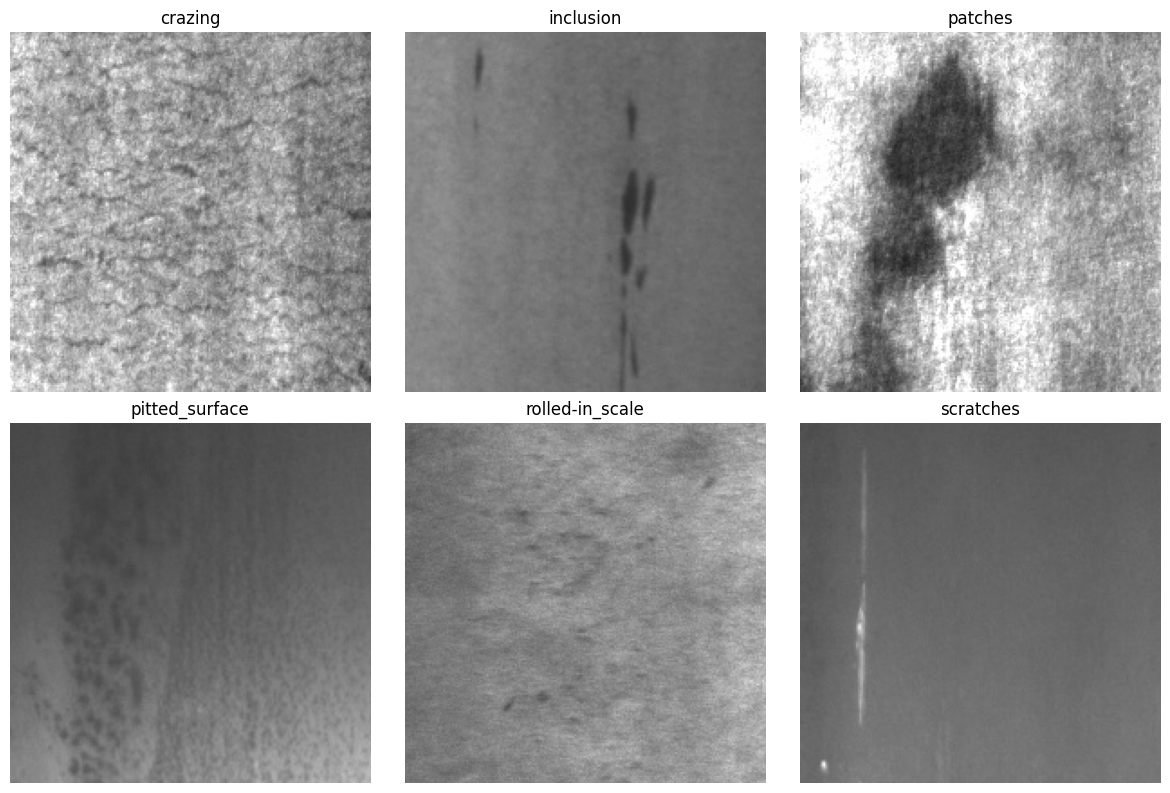

In [20]:

import os
import cv2
import matplotlib.pyplot as plt

image_folder = "/content/NEU_Dataset/NEU-DET/train/images"

classes = sorted(os.listdir(image_folder))

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):

    class_path = os.path.join(image_folder, class_name)

    image_files = sorted([
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    image_path = os.path.join(class_path, image_files[0])

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


Training class distribution:
crazing: 240
inclusion: 240
patches: 240
pitted_surface: 240
rolled-in_scale: 240
scratches: 240


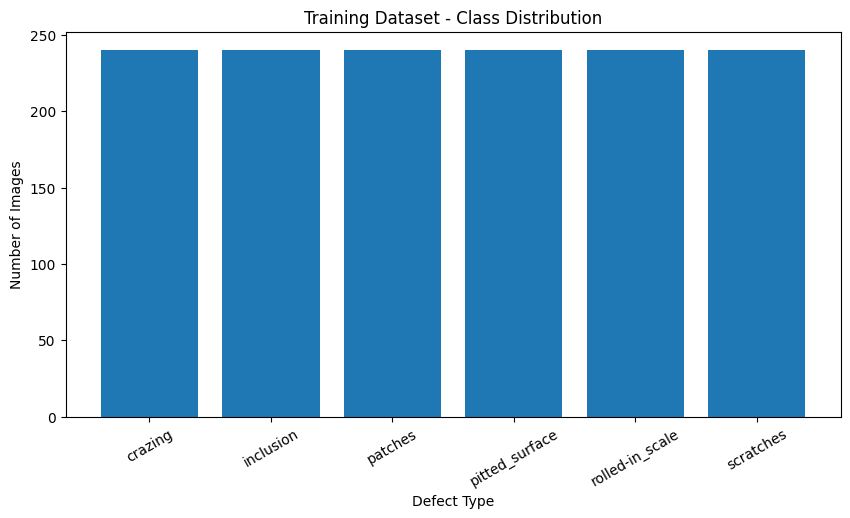

In [21]:

class_counts = {}

for class_name in classes:

    class_path = os.path.join(image_folder, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    class_counts[class_name] = count

print("Training class distribution:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Training Dataset - Class Distribution")
plt.xlabel("Defect Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()


In [22]:

import os

val_folder = "/content/NEU_Dataset/NEU-DET/validation/images"

val_counts = {}

for class_name in classes:

    class_path = os.path.join(val_folder, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    val_counts[class_name] = len(image_files)

print("Validation class distribution:")

for class_name, count in val_counts.items():
    print(f"{class_name}: {count}")

print("\nTotal validation images:", sum(val_counts.values()))


Validation class distribution:
crazing: 60
inclusion: 60
patches: 60
pitted_surface: 60
rolled-in_scale: 60
scratches: 60

Total validation images: 360


In [23]:

import torch
from torchvision import datasets, transforms

train_folder = "/content/NEU_Dataset/NEU-DET/train/images"
test_folder = "/content/NEU_Dataset/NEU-DET/validation/images"

# Basic image transformations
basic_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Load datasets
full_train_dataset = datasets.ImageFolder(
    root=train_folder,
    transform=basic_transform
)

test_dataset = datasets.ImageFolder(
    root=test_folder,
    transform=basic_transform
)

print("Training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))

print("\nClass names:")
print(full_train_dataset.classes)

print("\nClass-to-index mapping:")
print(full_train_dataset.class_to_idx)


Training images: 1440
Test images: 360

Class names:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Class-to-index mapping:
{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [24]:

import numpy as np
from sklearn.model_selection import train_test_split

# Get the numerical labels assigned by ImageFolder
labels = np.array(full_train_dataset.targets)

# Get the indices of all 1,440 images
indices = np.arange(len(full_train_dataset))

# Stratified 80/20 split
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_dataset))

# Verify class distribution
print("\nTraining class distribution:")
print(np.bincount(labels[train_indices]))

print("\nValidation class distribution:")
print(np.bincount(labels[val_indices]))


Training samples: 1152
Validation samples: 288
Test samples: 360

Training class distribution:
[192 192 192 192 192 192]

Validation class distribution:
[48 48 48 48 48 48]


In [25]:

from torchvision import datasets, transforms
from torch.utils.data import Subset

# ImageNet normalization values for pretrained ResNet18
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation and test transformations
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Separate ImageFolder objects so transforms stay independent
train_base = datasets.ImageFolder(
    root=train_folder,
    transform=train_transform
)

val_base = datasets.ImageFolder(
    root=train_folder,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    root=test_folder,
    transform=eval_transform
)

# Apply previously created stratified indices
train_dataset = Subset(train_base, train_indices)
val_dataset = Subset(val_base, val_indices)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))


Training dataset: 1152
Validation dataset: 288
Test dataset: 360


In [26]:

import torch
import torch.nn as nn

model = nn.Sequential(

    # First convolution block
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Second convolution block
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Third convolution block
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    # Fully connected layers
    nn.Flatten(),
    nn.Linear(64 * 28 * 28, 128),
    nn.ReLU(),
    nn.Dropout(0.5),

    # Output layer: 6 defect categories
    nn.Linear(128, 6)

).to(device)

print(model)


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=50176, out_features=128, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=128, out_features=6, bias=True)
)


In [27]:

import torch.nn as nn
import torch.optim as optim

# Loss function for multiclass classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Loss function: CrossEntropyLoss()
Optimizer: Adam


In [28]:

from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 36
Validation batches: 9
Test batches: 12


In [29]:

# Get one batch from the training loader
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Forward pass
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("First image logits:", outputs[0])


Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 6])
First image logits: tensor([ 0.0286,  0.0059,  0.0706, -0.0182, -0.0991, -0.0373], device='cuda:0')


In [30]:

model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Reset gradients
    optimizer.zero_grad()

    # Forward propagation
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Track loss and accuracy
    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

print("Training Loss:", running_loss / total)
print("Training Accuracy:", correct / total)


Training Loss: 1.2999949124124315
Training Accuracy: 0.5052083333333334


In [31]:

model.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print("Validation Loss:", val_loss / total)
print("Validation Accuracy:", correct / total)


Validation Loss: 0.7992963062392341
Validation Accuracy: 0.7361111111111112


In [32]:

for epoch in range(10):

    model.train()
    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    model.eval()
    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    print(
        f"Epoch {epoch+2}/11 | "
        f"Train Loss: {train_loss/len(train_dataset):.4f} | "
        f"Train Acc: {train_correct/len(train_dataset):.4f} | "
        f"Val Loss: {val_loss/len(val_dataset):.4f} | "
        f"Val Acc: {val_correct/len(val_dataset):.4f}"
    )


Epoch 2/11 | Train Loss: 0.6685 | Train Acc: 0.7578 | Val Loss: 0.5658 | Val Acc: 0.7951
Epoch 3/11 | Train Loss: 0.5339 | Train Acc: 0.8142 | Val Loss: 0.6209 | Val Acc: 0.7847
Epoch 4/11 | Train Loss: 0.4268 | Train Acc: 0.8550 | Val Loss: 0.3551 | Val Acc: 0.8715
Epoch 5/11 | Train Loss: 0.3593 | Train Acc: 0.8741 | Val Loss: 0.3582 | Val Acc: 0.8854
Epoch 6/11 | Train Loss: 0.3043 | Train Acc: 0.8941 | Val Loss: 0.2550 | Val Acc: 0.9167
Epoch 7/11 | Train Loss: 0.2863 | Train Acc: 0.9071 | Val Loss: 0.3546 | Val Acc: 0.8507
Epoch 8/11 | Train Loss: 0.2278 | Train Acc: 0.9297 | Val Loss: 0.2428 | Val Acc: 0.9028
Epoch 9/11 | Train Loss: 0.1983 | Train Acc: 0.9401 | Val Loss: 0.1863 | Val Acc: 0.9410
Epoch 10/11 | Train Loss: 0.1949 | Train Acc: 0.9297 | Val Loss: 0.2847 | Val Acc: 0.9028
Epoch 11/11 | Train Loss: 0.1822 | Train Acc: 0.9436 | Val Loss: 0.1886 | Val Acc: 0.9375


In [33]:

model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = test_correct / test_total

print("Test Accuracy:", test_accuracy)
print("Correct Predictions:", test_correct)
print("Total Test Images:", test_total)


Test Accuracy: 0.8805555555555555
Correct Predictions: 317
Total Test Images: 360


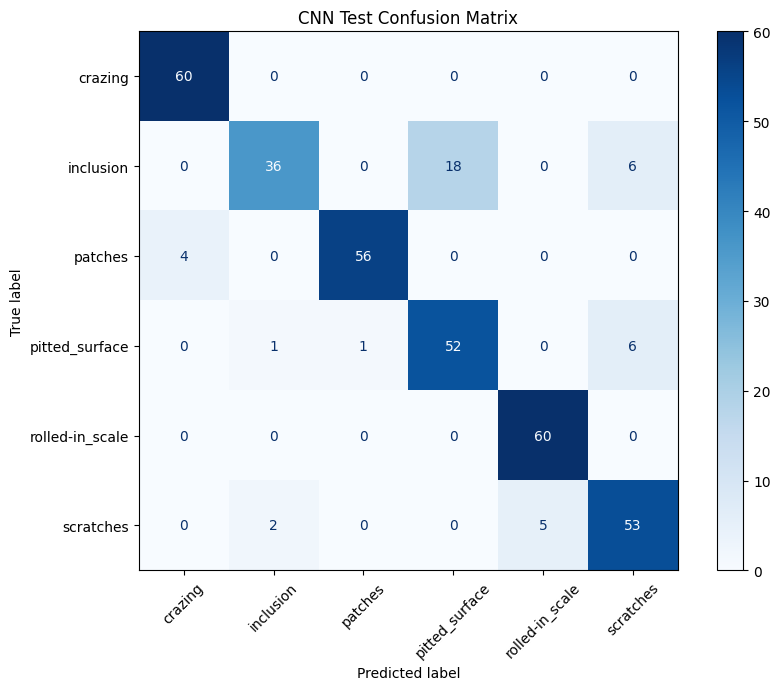

                 precision    recall  f1-score   support

        crazing       0.94      1.00      0.97        60
      inclusion       0.92      0.60      0.73        60
        patches       0.98      0.93      0.96        60
 pitted_surface       0.74      0.87      0.80        60
rolled-in_scale       0.92      1.00      0.96        60
      scratches       0.82      0.88      0.85        60

       accuracy                           0.88       360
      macro avg       0.89      0.88      0.88       360
   weighted avg       0.89      0.88      0.88       360



In [34]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = test_dataset.classes

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Test Confusion Matrix")
plt.show()

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))


In [35]:

from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))


                 precision    recall  f1-score   support

        crazing     0.9375    1.0000    0.9677        60
      inclusion     0.9231    0.6000    0.7273        60
        patches     0.9825    0.9333    0.9573        60
 pitted_surface     0.7429    0.8667    0.8000        60
rolled-in_scale     0.9231    1.0000    0.9600        60
      scratches     0.8154    0.8833    0.8480        60

       accuracy                         0.8806       360
      macro avg     0.8874    0.8806    0.8767       360
   weighted avg     0.8874    0.8806    0.8767       360



In [36]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet18
resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

print(resnet.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


Linear(in_features=512, out_features=1000, bias=True)


In [37]:

# Freeze pretrained parameters
for param in resnet.parameters():
    param.requires_grad = False

# Replace the classification layer
resnet.fc = nn.Linear(512, 6)

# Move model to GPU
resnet = resnet.to(device)

print(resnet.fc)


Linear(in_features=512, out_features=6, bias=True)


In [38]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    resnet.fc.parameters(),
    lr=0.001
)

print("ResNet18 ready for training!")


ResNet18 ready for training!


In [39]:

import torch
import copy

epochs = 10

best_val_loss = float("inf")
best_weights = None

for epoch in range(epochs):

    # Keep frozen ResNet features in evaluation mode
    resnet.eval()
    resnet.fc.train()

    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    # Validation
    resnet.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    val_loss /= len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    # Save best model in memory
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(resnet.state_dict())

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Restore best validation model
resnet.load_state_dict(best_weights)

print("\nBest validation loss:", round(best_val_loss, 4))


Epoch 1/10 | Train Loss: 1.1376 | Train Acc: 0.7040 | Val Loss: 0.6219 | Val Acc: 0.9583
Epoch 2/10 | Train Loss: 0.4286 | Train Acc: 0.9861 | Val Loss: 0.3214 | Val Acc: 0.9653
Epoch 3/10 | Train Loss: 0.2396 | Train Acc: 0.9913 | Val Loss: 0.2187 | Val Acc: 0.9792
Epoch 4/10 | Train Loss: 0.1677 | Train Acc: 0.9931 | Val Loss: 0.1686 | Val Acc: 0.9792
Epoch 5/10 | Train Loss: 0.1255 | Train Acc: 0.9948 | Val Loss: 0.1392 | Val Acc: 0.9792
Epoch 6/10 | Train Loss: 0.1001 | Train Acc: 0.9948 | Val Loss: 0.1190 | Val Acc: 0.9861
Epoch 7/10 | Train Loss: 0.0845 | Train Acc: 0.9948 | Val Loss: 0.1051 | Val Acc: 0.9826
Epoch 8/10 | Train Loss: 0.0716 | Train Acc: 0.9957 | Val Loss: 0.0932 | Val Acc: 0.9861
Epoch 9/10 | Train Loss: 0.0617 | Train Acc: 0.9965 | Val Loss: 0.0848 | Val Acc: 0.9826
Epoch 10/10 | Train Loss: 0.0553 | Train Acc: 0.9974 | Val Loss: 0.0782 | Val Acc: 0.9826

Best validation loss: 0.0782


In [40]:

resnet.eval()

all_resnet_preds = []
all_resnet_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)

        all_resnet_preds.extend(predictions.cpu().numpy())
        all_resnet_labels.extend(labels.numpy())

from sklearn.metrics import accuracy_score, f1_score

resnet_accuracy = accuracy_score(
    all_resnet_labels,
    all_resnet_preds
)

resnet_f1 = f1_score(
    all_resnet_labels,
    all_resnet_preds,
    average="macro"
)

print("ResNet18 Test Accuracy:", resnet_accuracy)
print("ResNet18 Macro F1:", resnet_f1)


ResNet18 Test Accuracy: 0.9888888888888889
ResNet18 Macro F1: 0.98883906704324


                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        60
      inclusion     1.0000    0.9500    0.9744        60
        patches     1.0000    1.0000    1.0000        60
 pitted_surface     0.9677    1.0000    0.9836        60
rolled-in_scale     0.9836    1.0000    0.9917        60
      scratches     0.9833    0.9833    0.9833        60

       accuracy                         0.9889       360
      macro avg     0.9891    0.9889    0.9888       360
   weighted avg     0.9891    0.9889    0.9888       360



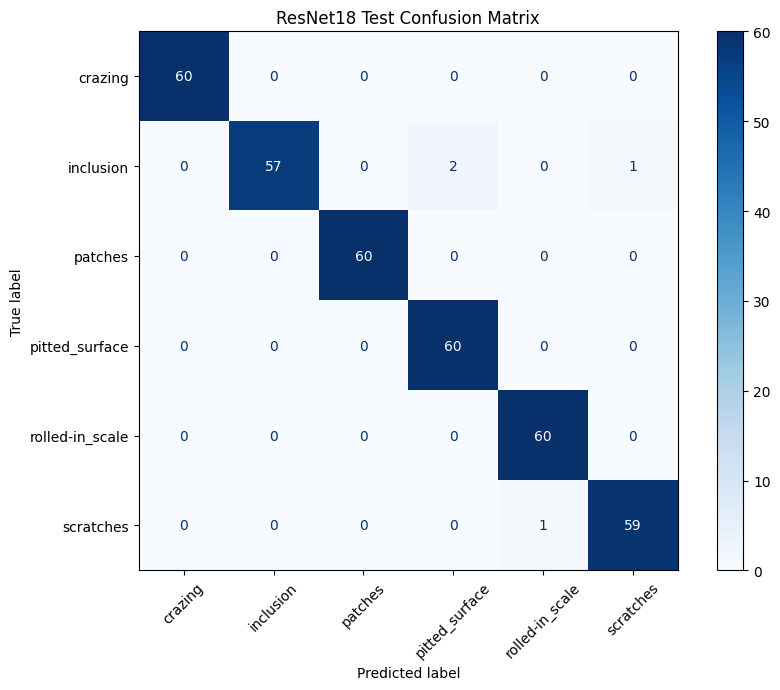

In [41]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(classification_report(
    all_resnet_labels,
    all_resnet_preds,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(
    all_resnet_labels,
    all_resnet_preds
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("ResNet18 Test Confusion Matrix")
plt.show()


In [42]:

torch.save(
    {
        "model_state_dict": resnet.state_dict(),
        "class_names": class_names
    },
    "/content/resnet18_steel_defects.pth"
)

print("ResNet18 model saved successfully!")


ResNet18 model saved successfully!


In [43]:

train_set = set(train_indices)
val_set = set(val_indices)

overlap = train_set.intersection(val_set)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Overlapping images:", len(overlap))


Training images: 1152
Validation images: 288
Overlapping images: 0


In [44]:

import hashlib

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

train_paths = [
    train_base.samples[i][0]
    for i in train_indices
]

val_paths = [
    val_base.samples[i][0]
    for i in val_indices
]

test_paths = [
    test_dataset.samples[i][0]
    for i in range(len(test_dataset))
]

train_hashes = set(image_hash(p) for p in train_paths)
val_hashes = set(image_hash(p) for p in val_paths)
test_hashes = set(image_hash(p) for p in test_paths)

print("Train-Val duplicates:", len(train_hashes & val_hashes))
print("Train-Test duplicates:", len(train_hashes & test_hashes))
print("Val-Test duplicates:", len(val_hashes & test_hashes))


Train-Val duplicates: 1
Train-Test duplicates: 0
Val-Test duplicates: 0


In [45]:

from collections import defaultdict

train_hash_map = defaultdict(list)
val_hash_map = defaultdict(list)

for path in train_paths:
    train_hash_map[image_hash(path)].append(path)

for path in val_paths:
    val_hash_map[image_hash(path)].append(path)

common_hashes = set(train_hash_map) & set(val_hash_map)

for h in common_hashes:
    print("Training file:", train_hash_map[h])
    print("Validation file:", val_hash_map[h])


Training file: ['/content/NEU_Dataset/NEU-DET/train/images/patches/patches_105.jpg']
Validation file: ['/content/NEU_Dataset/NEU-DET/train/images/patches/patches_101.jpg']


In [46]:

import torch

torch.save({
    "model_state_dict": resnet.state_dict(),
    "class_names": class_names
}, "/content/resnet18_steel_defects.pth")

print("Model saved successfully!")


Model saved successfully!
